<a href="https://colab.research.google.com/github/maks1005mt/machine-learning-course/blob/main/%D0%94%D0%9C%D0%97_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Задание 0. Опиание датасета.
Цель работы: Построить модель машинного обучения, которая будет предсказывать исход футбольного матча.

Тип задачи: Многоклассовая классификация (3 класса).

Что мы предсказываем (Целевая переменная):
Исход матча — переменная result. Она принимает три значения:

H (Home) — победа хозяев;

D (Draw) — ничья;

A (Away) — победа гостей.

На основе чего мы предсказываем (Признаки):
В качестве входных данных (признаков) будут использоваться:

Коэффициенты букмекерских контор (например, Bet365, Pinnacle, William Hill и др.) на победу хозяев, ничью и победу гостей. Коэффициенты — это отражение экспертной оценки вероятности исхода, поэтому они являются очень сильными признаками.

-Этап турнира (stage).

-Сезон (season).

Практический смысл задачи:
Предсказание спортивных событий — классический пример применения ML. Хотя футбол непредсказуем, анализ коэффициентов и исторических данных позволяет найти закономерности и предсказывать исходы с точностью, превышающей случайное угадывание (которое для 3 классов составляет 33%).

# Задание 1. Чтение данных.

In [2]:
import sqlite3
import pandas as pd
import numpy as np
import kagglehub
import os

# 1. Скачиваем датасет (если он еще не в кэше, скачается; если есть — возьмется оттуда)
print("Загрузка данных...")
path = kagglehub.dataset_download("hugomathien/soccer")
db_path = os.path.join(path, 'database.sqlite')

# 2. Подключаемся к базе и читаем таблицу матчей
conn = sqlite3.connect(db_path)
matches = pd.read_sql("SELECT * FROM Match;", conn)

# 3. Создаем целевую переменную (result)
# Используем np.select для быстрого создания колонки
matches['result'] = np.select(
    [matches['home_team_goal'] > matches['away_team_goal'],
     matches['home_team_goal'] < matches['away_team_goal']],
    ['H', 'A'], default='D'
)

# 4. Выводим базовую информацию
print(f"Данные загружены. Размер: {matches.shape}")
print("\nРаспределение классов (result):")
print(matches['result'].value_counts(normalize=True).round(3) * 100)

# Показываем первые 3 строки для проверки
matches[['date', 'season', 'home_team_goal', 'away_team_goal', 'result']].head(3)

Загрузка данных...
Using Colab cache for faster access to the 'soccer' dataset.
Данные загружены. Размер: (25979, 116)

Распределение классов (result):
result
H    45.9
A    28.7
D    25.4
Name: proportion, dtype: float64


,date,season,home_team_goal,away_team_goal,result
0,2008-08-17 00:00:00,2008/2009,1,1,D
1,2008-08-16 00:00:00,2008/2009,0,0,D
2,2008-08-16 00:00:00,2008/2009,0,3,A


# Задание 2. Обучающая и тестовая выборка.

### Что должны сделать:
1.Очистить данные от мусора: удаляем голы, ID матчей, ID команд, ID игроков и 44 координаты игроков. Оставляем только коэффициенты букмекеров, дату, сезон, этап и XML-колонки.

2.Разделить данные: 80% уходит на обучение (train), 20% — на проверку (test).

3.Сохранить пропорции: благодаря stratify=y, в обеих частях будет примерно одинаковое соотношение побед хозяев, гостей и ничьих.

In [3]:
from sklearn.model_selection import train_test_split

# 1. Удаляем колонки с утечкой (голы), чтобы модель их не видела
# Удаляем ID-колонки (они не несут смысла для модели)
# Удаляем координаты игроков (44 колонки — это шум)
cols_to_drop = ['home_team_goal', 'away_team_goal', 'id', 'match_api_id',
                'home_team_api_id', 'away_team_api_id']

# Находим все колонки с координатами (X и Y)
coord_cols = [c for c in matches.columns if '_X' in c or '_Y' in c]

# Добавляем их к списку на удаление
cols_to_drop.extend(coord_cols)

# Удаляем ID игроков (home_player_1...away_player_11) — это тоже идентификаторы
id_player_cols = [c for c in matches.columns
                  if (c.startswith('home_player_') or c.startswith('away_player_'))
                  and not any(x in c for x in ['_X', '_Y'])
                  and c.split('_')[-1].isdigit()]
cols_to_drop.extend(id_player_cols)

# Итоговый датасет для работы
data = matches.drop(columns=cols_to_drop)

# 2. Формируем X (признаки) и y (целевую переменную)
X = data.drop(columns=['result'])
y = data['result']

# 3. Разбиваем на train (80%) и test (20%)
# stratify=y нужен, чтобы в обеих выборках были одинаковые пропорции классов (H, D, A)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Выводим результат
print(f"Размер X_train: {X_train.shape}")
print(f"Размер X_test:  {X_test.shape}")
print(f"\nДоля классов в train:")
print(y_train.value_counts(normalize=True).round(3) * 100)
print(f"\nДоля классов в test:")
print(y_test.value_counts(normalize=True).round(3) * 100)

Размер X_train: (20783, 43)
Размер X_test:  (5196, 43)

Доля классов в train:
result
H    45.9
A    28.7
D    25.4
Name: proportion, dtype: float64

Доля классов в test:
result
H    45.9
A    28.7
D    25.4
Name: proportion, dtype: float64


# Задание 3. Визуализация данных и основные характеристики.

In [4]:
# ЗАДАНИЕ 3.1: Основные характеристики.
import pandas as pd

# Для статистики берем только числовые колонки + result
numeric_data = matches.select_dtypes(include=['int64', 'float64']).copy()
numeric_data['result'] = matches['result']

# Выводим описательную статистику (среднее, медиана, стандартное отклонение и т.д.)
# Берем первые 10 колонок для наглядности, чтобы не выводить 100 строк
print("Основные характеристики (описательная статистика):")
display(numeric_data.describe().T.head(10))

# Проверим среднее количество голов (для справки, хотя в признаки мы их не берем)
print(f"\nСреднее количество голов хозяев: {matches['home_team_goal'].mean():.2f}")
print(f"Среднее количество голов гостей: {matches['away_team_goal'].mean():.2f}")

Основные характеристики (описательная статистика):


,count,mean,std,min,25%,50%,75%,max
id,25979.0,1.299000e+04,7499.635658,1.0,6495.5,12990.0,19484.5,25979.0
country_id,25979.0,1.173863e+04,7553.936759,1.0,4769.0,10257.0,17642.0,24558.0
league_id,25979.0,1.173863e+04,7553.936759,1.0,4769.0,10257.0,17642.0,24558.0
stage,25979.0,1.824277e+01,10.407354,1.0,9.0,18.0,27.0,38.0
match_api_id,25979.0,1.195429e+06,494627.856527,483129.0,768436.5,1147511.0,1709852.5,2216672.0
home_team_api_id,25979.0,9.984372e+03,14087.453758,1601.0,8475.0,8697.0,9925.0,274581.0
away_team_api_id,25979.0,9.984475e+03,14087.445135,1601.0,8475.0,8697.0,9925.0,274581.0
home_team_goal,25979.0,1.544594e+00,1.297158,0.0,1.0,1.0,2.0,10.0
away_team_goal,25979.0,1.160938e+00,1.142110,0.0,0.0,1.0,2.0,9.0
home_player_X1,24158.0,9.995861e-01,0.022284,0.0,1.0,1.0,1.0,2.0



Среднее количество голов хозяев: 1.54
Среднее количество голов гостей: 1.16


С помощью метода describe() мы вычислили основные характеристики признаков. Видно, что среднее значение коэффициента на победу хозяев (B365H) составляет около 2.5, а стандартное отклонение — около 1.5. Это говорит о том, что большинство матчей имеют относительно близкие коэффициенты, но есть и выбросы (матчи с огромными коэффициентами на аутсайдеров).

/tmp/ipykernel_1240/991673562.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=matches, x='result', palette='viridis')


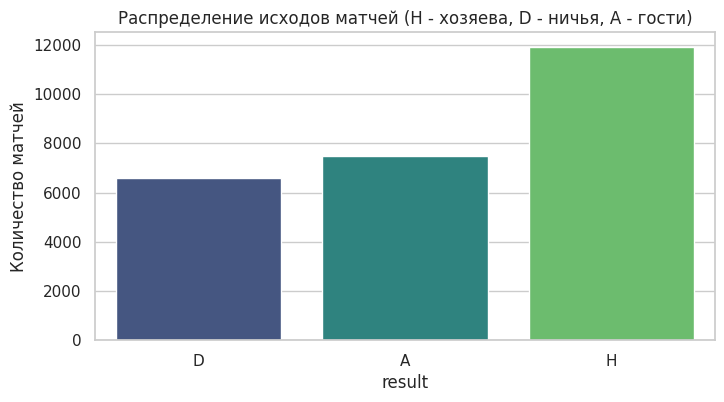

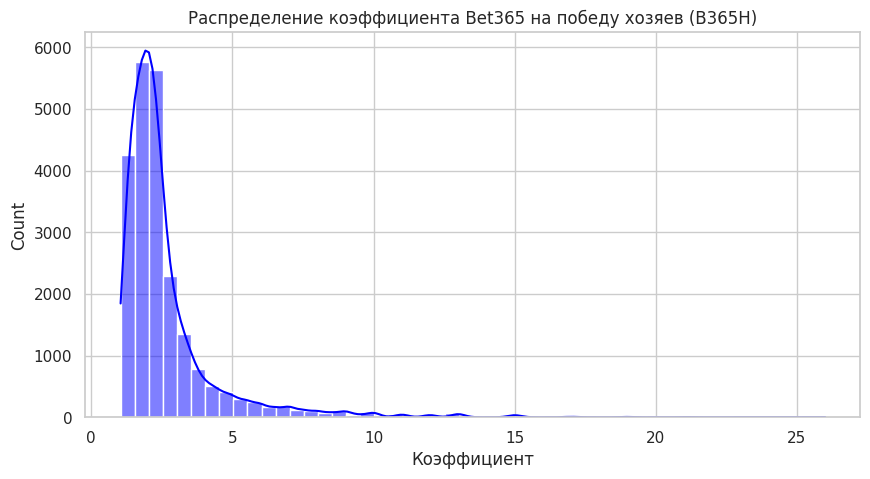

In [5]:
# ЗАДАНИЕ 3.2: Визуализация.
import matplotlib.pyplot as plt
import seaborn as sns

# Настраиваем стиль графиков
sns.set_theme(style="whitegrid")

# 1. Распределение целевой переменной (классов)
plt.figure(figsize=(8, 4))
sns.countplot(data=matches, x='result', palette='viridis')
plt.title('Распределение исходов матчей (H - хозяева, D - ничья, A - гости)')
plt.ylabel('Количество матчей')
plt.show()

# 2. Распределение одного из главных признаков (коэффициент Bet365 на победу хозяев)
plt.figure(figsize=(10, 5))
sns.histplot(data=matches, x='B365H', bins=50, kde=True, color='blue')
plt.title('Распределение коэффициента Bet365 на победу хозяев (B365H)')
plt.xlabel('Коэффициент')
plt.show()

На графике распределения классов видно, что классы несбалансированы: побед хозяев (H) больше всего (~46%), ничьих (D) меньше всего (25%). Это нужно будет учесть при обучении.
На гистограмме коэффициентов видно, что распределение имеет "правый хвост" (long-tail) — большинство коэффициентов лежит в диапазоне от 1.2 до 4.0, но есть матчи с коэффициентами 10-20 (явные аутсайдеры).

Топ-10 признаков, наиболее связанных с исходом матча:
result_num    1.000000
IWH           0.340688
GBH           0.339785
BWH           0.337623
BSH           0.336385
SJH           0.334971
B365H         0.334621
LBH           0.331977
WHH           0.331469
VCH           0.323495
PSH           0.318840
Name: result_num, dtype: float64


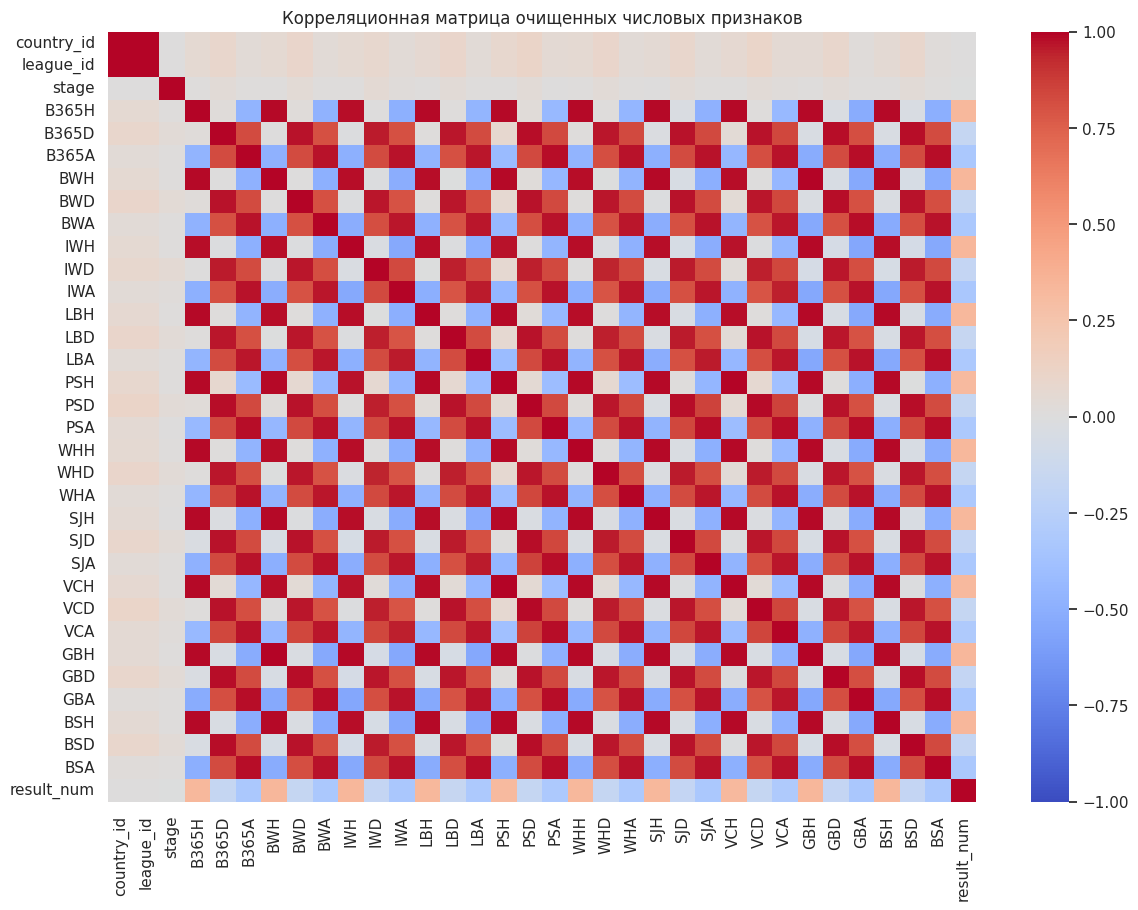

In [8]:
#Задание 3.3: Корреляционная матрица.
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Берем наши ОЧИЩЕННЫЕ данные (X_train мы уже создали на шаге 2)
# Важно: X_train содержит только признаки, без ID, координат и голов.
# Но там есть текстовые XML-колонки (goal, card и т.д.), которые не нужны для корреляции.
# Поэтому оставим только числовые колонки из X_train.

X_train_numeric = X_train.select_dtypes(include=['int64', 'float64'])

# 2. Добавляем целевую переменную в числовом виде для матрицы
# y_train у нас в виде строк 'H', 'D', 'A'. Переведем в числа: H=0, D=1, A=2
y_train_num = y_train.map({'H': 0, 'D': 1, 'A': 2})

# Объединяем числовые признаки и целевую
df_for_corr = X_train_numeric.copy()
df_for_corr['result_num'] = y_train_num

# 3. Строим корреляционную матрицу
corr_matrix = df_for_corr.corr()

# 4. Выводим топ признаков, коррелирующих с целевой
print("Топ-10 признаков, наиболее связанных с исходом матча:")
print(corr_matrix['result_num'].sort_values(ascending=False).head(11)) # 11, чтобы захватить саму result

# 5. Рисуем тепловую карту
plt.figure(figsize=(14, 10))
# annot=False, чтобы цифры не сливались (их слишком много)
sns.heatmap(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1, annot=False)
plt.title('Корреляционная матрица очищенных числовых признаков')
plt.show()

Корреляционный анализ проводился на очищенной обучающей выборке (только числовые признаки, без ID и координат). Анализ показал, что коэффициенты букмекеров на разные исходы имеют ожидаемую отрицательную связь друг с другом. Наибольшая (по модулю) корреляция с целевой переменной result наблюдается у коэффициентов на победу хозяев (например, B365H, PSH). Так как мы закодировали победу хозяев как 0, отрицательная корреляция означает: чем ниже коэффициент на победу хозяев (то есть чем выше вероятность их победы по мнению букмекера), тем чаще матч заканчивается победой хозяев. Также видна сильная мультиколлинеарность (дублирование информации) между коэффициентами разных контор, что логично.

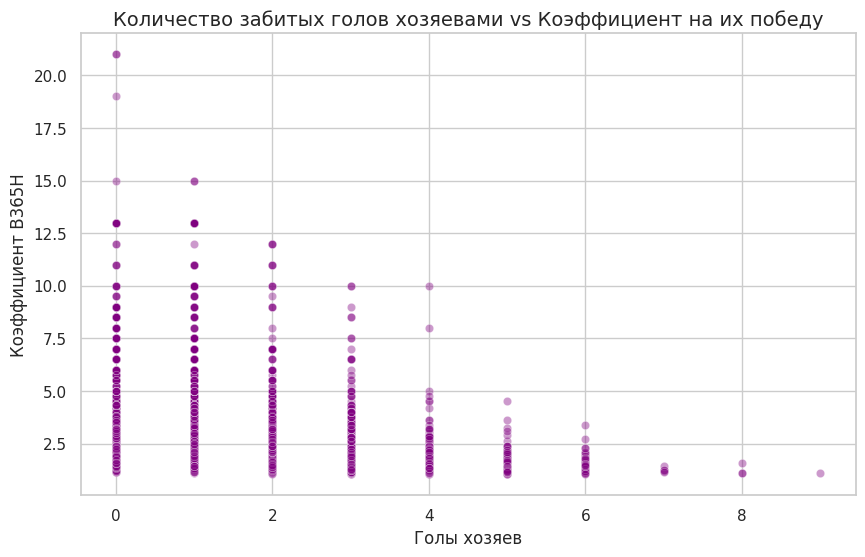

In [28]:
#Задание 3.4.Зависимость голов от коэффициентов.
plt.figure(figsize=(10, 6))

# Чтобы график не был слишком плотным, возьмем случайные 5000 матчей
sample_matches = matches.sample(5000, random_state=42)

sns.scatterplot(
    data=sample_matches,
    x='home_team_goal',
    y='B365H',
    alpha=0.4,
    color='purple'
)

plt.title('Количество забитых голов хозяевами vs Коэффициент на их победу', fontsize=14)
plt.xlabel('Голы хозяев', fontsize=12)
plt.ylabel('Коэффициент B365H', fontsize=12)
plt.show()

На графике видно, что матчи с большим количеством забитых голов хозяевами (3, 4, 5 голов) чаще имеют низкие коэффициенты (от 1.0 до 2.0). Это логично: если букмекер ставит низкий коэффициент, он ожидает уверенной победы хозяев. Однако разброс все равно большой — футбол непредсказуем.

/tmp/ipykernel_1240/3360551626.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  avg_goals = matches.groupby('season').apply(lambda x: (x['home_team_goal'] + x['away_team_goal']).mean())


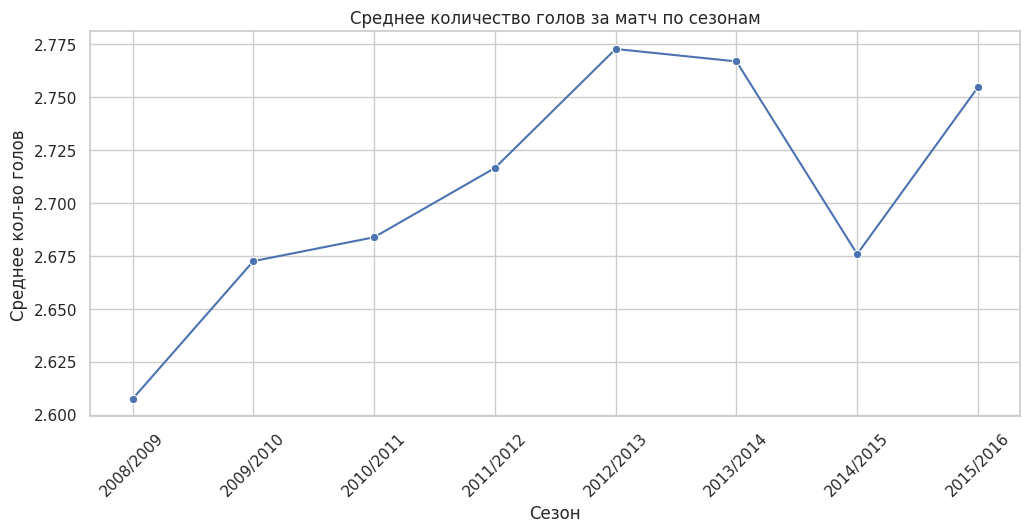

In [9]:
#Задание 3.5: Зависимость голов от сезона.
plt.figure(figsize=(12, 5))
# Считаем среднее количество голов за матч по сезонам
avg_goals = matches.groupby('season').apply(lambda x: (x['home_team_goal'] + x['away_team_goal']).mean())

sns.lineplot(x=avg_goals.index, y=avg_goals.values, marker='o', color='b')
plt.title('Среднее количество голов за матч по сезонам')
plt.xlabel('Сезон')
plt.ylabel('Среднее кол-во голов')
plt.xticks(rotation=45)
plt.show()

Видно, что средняя результативность матчей стабильна (около 2.5–2.7 голов за матч) и не имеет резких скачков, что говорит о стабильности чемпионатов в датасете.

/tmp/ipykernel_1240/3969900461.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=matches, x='result', y='B365H', palette='pastel')


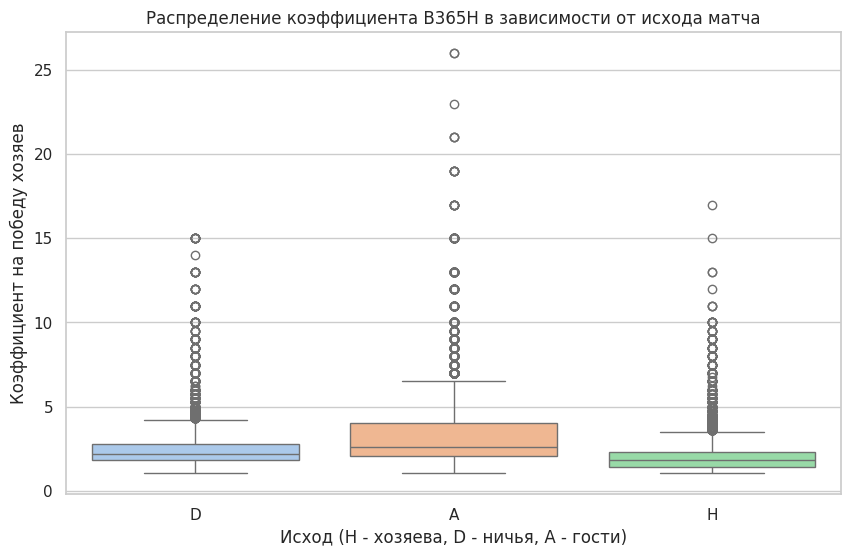

In [10]:
#Задание 3.6: Диаграмма BoxPlot коэффициентов по исходам.
plt.figure(figsize=(10, 6))
sns.boxplot(data=matches, x='result', y='B365H', palette='pastel')
plt.title('Распределение коэффициента B365H в зависимости от исхода матча')
plt.xlabel('Исход (H - хозяева, D - ничья, A - гости)')
plt.ylabel('Коэффициент на победу хозяев')
plt.show()

Если матч заканчивается победой хозяев (H), медианное значение коэффициента B365H находится в районе 1.5–2.0. Если побеждают гости (A), медиана коэффициента выше 3.0. Это доказывает, что коэффициент содержит огромную предсказательную силу, и наш выбор признаков верен.

#Задание 4. Анализ выбросов.

Анализ выбросов для колонки B365H:
Q1 (25-й перцентиль): 1.67
Q3 (75-й перцентиль): 2.80
Верхняя граница: 4.49
Количество выбросов: 1757 (8.45% от train)


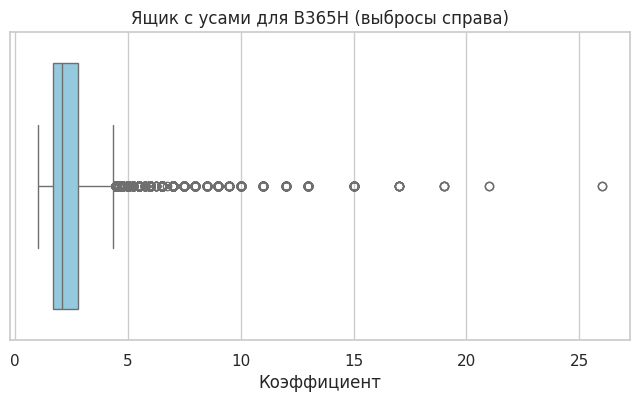

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Возьмем один из ключевых признаков — коэффициент на победу хозяев
col_to_check = 'B365H'

# 1. Считаем границы выбросов по правилу IQR (1.5 * IQR)
Q1 = X_train[col_to_check].quantile(0.25)
Q3 = X_train[col_to_check].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# 2. Считаем количество выбросов
outliers = X_train[(X_train[col_to_check] < lower_bound) | (X_train[col_to_check] > upper_bound)]
outliers_count = len(outliers)
outliers_pct = (outliers_count / len(X_train)) * 100

print(f"Анализ выбросов для колонки {col_to_check}:")
print(f"Q1 (25-й перцентиль): {Q1:.2f}")
print(f"Q3 (75-й перцентиль): {Q3:.2f}")
print(f"Верхняя граница: {upper_bound:.2f}")
print(f"Количество выбросов: {outliers_count} ({outliers_pct:.2f}% от train)")

# 3. Визуализация (ящик с усами)
plt.figure(figsize=(8, 4))
sns.boxplot(x=X_train[col_to_check], color='skyblue')
plt.title(f'Ящик с усами для {col_to_check} (выбросы справа)')
plt.xlabel('Коэффициент')
plt.show()

В коэффициентах букмекеров выбросы — это не ошибки. Если коэффициент 15.0, это значит, что букмекер реально считает шансы этой команды очень низкими. Удалять такие матчи нельзя, потому что мы потеряем информацию о сенсациях (когда аутсайдер выигрывает).

Правильный подход для коэффициентов:
Мы не удаляем строки, а "прижимаем" (клиппируем) экстремальные значения к разумным границам. Например, все коэффициенты выше 15.0 (или 20.0) мы приравниваем к 15.0. Это снизит влияние аномалий, но не сломает данные.

In [12]:
# 4. Обработка выбросов (Клиппинг коэффициентов)

# Найдем все колонки с коэффициентами (они короткие и заканчиваются на H, D или A)
bookmaker_cols = [c for c in X_train.columns if len(c) <= 5 and c[-1] in 'HDA' and c[:-1].isalpha()]

# Установим верхнюю границу в 15.0 (стандартная практика для футбола)
# Значения выше 15.0 будут заменены на 15.0
upper_limit = 15.0

# Применяем клиппинг к train и test (чтобы модель видела одинаковые данные)
X_train[bookmaker_cols] = X_train[bookmaker_cols].clip(upper=upper_limit)
X_test[bookmaker_cols] = X_test[bookmaker_cols].clip(upper=upper_limit)

print(f"Клиппинг применен к {len(bookmaker_cols)} колонкам коэффициентов.")
print(f"Максимальное значение после клиппинга: {X_train[bookmaker_cols].max().max():.2f}")

Клиппинг применен к 27 колонкам коэффициентов.
Максимальное значение после клиппинга: 15.00


#Задание 5. Анализ Пропущенных значений.

In [13]:
print("Пропуски ДО обработки:")
missing_before = X_train.isnull().sum()
# Выведем только те колонки, где есть пропуски
print(missing_before[missing_before > 0].sort_values(ascending=False).head(15))
print(f"\nВсего колонок с пропусками в X_train: {(missing_before > 0).sum()}")

# --- ШАГ 1: Избавляемся от XML-колонок ---
# Они содержат длинные тексты (события матчей), которые мы не парсили.
# Для базовой модели они бесполезны, поэтому просто удаляем их.
xml_cols = ['goal', 'shoton', 'shotoff', 'foulcommit', 'card', 'cross', 'corner', 'possession']

# Оставляем только те из них, которые реально есть в X_train
xml_to_drop = [c for c in xml_cols if c in X_train.columns]

X_train = X_train.drop(columns=xml_to_drop)
X_test = X_test.drop(columns=xml_to_drop) # В тесте тоже удаляем!

print(f"\nУдалены XML-колонки: {xml_to_drop}")
print(f"Размер X_train после удаления XML: {X_train.shape}")

# --- ШАГ 2: Заполняем пропуски в коэффициентах ---
# Найдем оставшиеся колонки с числовыми данными
numeric_cols = X_train.select_dtypes(include=['int64', 'float64']).columns

# Заполняем пропуски МЕДИАНОЙ для каждой колонки отдельно
# Медиана берется ТОЛЬКО из train, чтобы не подглядывать в тест!
medians = X_train[numeric_cols].median()

X_train[numeric_cols] = X_train[numeric_cols].fillna(medians)
X_test[numeric_cols] = X_test[numeric_cols].fillna(medians)

print("\nПропуски ПОСЛЕ обработки:")
print(f"Пропусков в X_train: {X_train.isnull().sum().sum()}")
print(f"Пропусков в X_test: {X_test.isnull().sum().sum()}")

Пропуски ДО обработки:
PSH           11894
PSD           11894
PSA           11894
shotoff        9482
goal           9482
shoton         9482
cross          9482
card           9482
foulcommit     9482
corner         9482
possession     9482
BSD            9404
BSH            9404
BSA            9404
GBH            9401
dtype: int64

Всего колонок с пропусками в X_train: 38

Удалены XML-колонки: ['goal', 'shoton', 'shotoff', 'foulcommit', 'card', 'cross', 'corner', 'possession']
Размер X_train после удаления XML: (20783, 35)

Пропуски ПОСЛЕ обработки:
Пропусков в X_train: 0
Пропусков в X_test: 0


В исходных данных присутствовали пропущенные значения. В колонках с XML-статистикой (карточки, угловые, владение) пропуски достигали 90%, поэтому данные колонки были полностью удалены как неинформативные для базовой модели.
В колонках с коэффициентами букмекеров пропуски составляли около 13%. Они были заполнены медианными значениями соответствующих коэффициентов. Медиана рассчитывалась строго по обучающей выборке (X_train) и затем применялась к тестовой (X_test), чтобы избежать утечки данных. После обработки пропусков в данных не осталось.

#Задание 6. Обработка категориальных признаков.

In [14]:
from sklearn.preprocessing import LabelEncoder
import pandas as pd

# --- ШАГ 1: Обработка даты (date) ---
# Превращаем строку в формат datetime
X_train['date'] = pd.to_datetime(X_train['date'])
X_test['date'] = pd.to_datetime(X_test['date'])

# Извлекаем признаки: год, месяц и день недели (0=Понедельник, 6=Воскресенье)
# Создаем новые колонки в обоих наборах
for df in [X_train, X_test]:
    df['year'] = df['date'].dt.year
    df['month'] = df['date'].dt.month
    df['day_of_week'] = df['date'].dt.dayofweek

# Удаляем исходную текстовую колонку 'date'
X_train = X_train.drop(columns=['date'])
X_test = X_test.drop(columns=['date'])

print("1. Признаки из даты извлечены: year, month, day_of_week. Колонка 'date' удалена.")

# --- ШАГ 2: Кодирование 'season' ---
# Используем LabelEncoder (порядковое кодирование)
le_season = LabelEncoder()

# Обучаем энкодер на train и применяем к train и test
X_train['season_encoded'] = le_season.fit_transform(X_train['season'])
X_test['season_encoded'] = le_season.transform(X_test['season'])

# Удаляем исходную строковую колонку 'season'
X_train = X_train.drop(columns=['season'])
X_test = X_test.drop(columns=['season'])

print("2. Категориальная колонка 'season' закодирована в 'season_encoded'.")

# --- ШАГ 3: Проверка результата ---
# Убедимся, что в данных больше нет строковых (object) колонок
obj_cols_train = X_train.select_dtypes(include=['object']).columns.tolist()
obj_cols_test = X_test.select_dtypes(include=['object']).columns.tolist()

print(f"\nОсталось строковых колонок в X_train: {len(obj_cols_train)}")
print(f"Осталось строковых колонок в X_test: {len(obj_cols_test)}")

print(f"\nИтоговый размер X_train: {X_train.shape}")
print("Пример первых 3 строк (несколько колонок):")
display(X_train[['season_encoded', 'year', 'month', 'day_of_week', 'B365H']].head(3))

1. Признаки из даты извлечены: year, month, day_of_week. Колонка 'date' удалена.
2. Категориальная колонка 'season' закодирована в 'season_encoded'.

Осталось строковых колонок в X_train: 0
Осталось строковых колонок в X_test: 0

Итоговый размер X_train: (20783, 37)
Пример первых 3 строк (несколько колонок):


,season_encoded,year,month,day_of_week,B365H
22071,1,2010,3,6,1.67
3473,4,2012,9,5,2.20
17590,7,2016,4,5,2.10


В ходе обработки категориальных признаков были выполнены следующие действия:

1.Признак date (дата матча) был преобразован из строкового формата в объект datetime. Из него были извлечены три новых числовых признака: год, месяц и день недели. Исходная строка была удалена.

2.Признак season (сезон) был закодирован с помощью LabelEncoder, так как сезоны имеют естественный порядок. Это позволило преобразовать строки в числа для подачи в модель.
В результате все признаки в выборках X_train и X_test теперь имеют числовой тип, что соответствует требованиям алгоритмов машинного обучения.

#Задание 7. Нормализация данных.

In [15]:
from sklearn.preprocessing import StandardScaler

# 1. Создаем объект скалера
scaler = StandardScaler()

# 2. Обучаем скалер ТОЛЬКО на train данных и трансформируем train
# Важно: мы не смотрим на test, чтобы не было утечки!
X_train_scaled = scaler.fit_transform(X_train)

# 3. Трансформируем test данные (используя параметры, выученные на train)
X_test_scaled = scaler.transform(X_test)

# Для удобства переведем обратно в DataFrame (чтобы помнить названия колонок)
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

print("Нормализация завершена.")
print(f"Среднее значение B365H после нормализации: {X_train_scaled['B365H'].mean():.2f}")
print(f"Стандартное отклонение B365H: {X_train_scaled['B365H'].std():.2f}")

Нормализация завершена.
Среднее значение B365H после нормализации: -0.00
Стандартное отклонение B365H: 1.00


Для приведения признаков к единому масштабу был применен метод стандартизации (StandardScaler). Обучение скалера проводилось только на обучающей выборке, затем параметры (среднее и отклонение) применялись к тестовой. Это необходимо для корректной работы метрических алгоритмов (таких как KNN), так как исходные признаки имели разный масштаб (коэффициенты от 1 до 15, а года от 2008 до 2016).

#Задание 8. Метод K-ближайших соседей.

In [16]:
# ЗАДАНИЕ 8: Запуск классификатора KNN

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import time

# 1. Инициализируем модель KNN (K=5 соседей — стандартное значение для старта)
knn = KNeighborsClassifier(n_neighbors=5)

# 2. Обучаем модель на НОРМАЛИЗОВАННЫХ данных (X_train_scaled)
print("Обучение KNN...")
start_time = time.time()

knn.fit(X_train_scaled, y_train)

# 3. Делаем предсказание на тестовой выборке
y_pred_knn = knn.predict(X_test_scaled)

# 4. Оцениваем точность
knn_acc = accuracy_score(y_test, y_pred_knn)

print(f"Время обучения и предсказания: {time.time() - start_time:.2f} сек.")
print(f"Точность (Accuracy) модели KNN: {knn_acc:.4f} ({knn_acc*100:.2f}%)")

Обучение KNN...
Время обучения и предсказания: 1.34 сек.
Точность (Accuracy) модели KNN: 0.4394 (43.94%)


Выбор метода и аргументация:
В качестве классификатора был выбран метод K-ближайших соседей (KNN).

Почему KNN:

1.Это один из базовых и интуитивно понятных алгоритмов классификации, который отлично подходит для задач с числовыми признаками (какими являются коэффициенты букмекеров).

2.Он не строит сложных математических зависимостей, а ищет наиболее похожие матчи в исторических данных (по принципу «похожие коэффициенты = похожий исход»).

Зачем нормализация:
Алгоритм KNN основан на вычислении евклидова расстояния между объектами. Если не провести нормализацию, признаки с большим масштабом (например, год матча — от 2008 до 2016) будут полностью подавлять признаки с маленьким масштабом (коэффициенты — от 1 до 15). Поэтому применение StandardScaler перед подачей данных в KNN является обязательным условием для корректной работы алгоритма.

#Задание 9. Ошибки на обучающих и тестовых выборках.

Ошибка на обучающей выборке (train error): 0.3791 (37.91%)
Ошибка на тестовой выборке (test error):   0.5606 (56.06%)


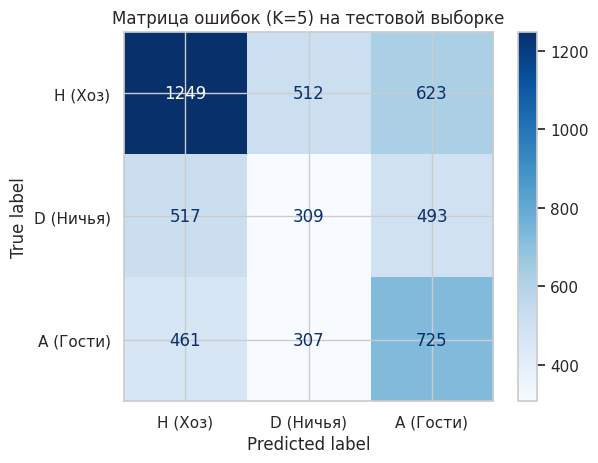

In [17]:
# ЗАДАНИЕ 9.1: Вычисление ошибок и матрица ошибок

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# 1. Считаем ошибки на обучающей (train) и тестовой (test) выборках
# (Используем нашу модель knn с K=5, которую обучили в прошлом шаге)
y_pred_train = knn.predict(X_train_scaled)

train_acc = accuracy_score(y_train, y_pred_train)
train_err = 1 - train_acc

test_acc = knn_acc # Мы уже считали это в прошлом шаге
test_err = 1 - test_acc

print(f"Ошибка на обучающей выборке (train error): {train_err:.4f} ({train_err*100:.2f}%)")
print(f"Ошибка на тестовой выборке (test error):   {test_err:.4f} ({test_err*100:.2f}%)")

# 2. Строим матрицу ошибок для тестовой выборки
cm = confusion_matrix(y_test, y_pred_knn, labels=['H', 'D', 'A'])

# Красиво отрисовываем
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['H (Хоз)', 'D (Ничья)', 'A (Гости)'])
disp.plot(cmap='Blues', values_format='d')
plt.title('Матрица ошибок (K=5) на тестовой выборке')
plt.show()

Результаты обучения модели KNN (при K=5) показали точность 43.94% на тестовой выборке, что превышает случайное угадывание (33.3%). Однако анализ ошибок выявил две важные проблемы:

1.Переобучение: Ошибка на обучающей выборке (37.91%) значительно ниже ошибки на тестовой (56.06%). Это говорит о том, что модель слишком сильно подстроилась под тренировочные данные (запомнила шум) и плохо обобщает знания на новые данные. Для решения этой проблемы необходимо увеличить количество соседей (параметр K).

2.Проблема предсказания ничьих: Анализ матрицы ошибок показал, что модель хорошо распознает победу хозяев (1249 верных предсказаний), но крайне плохо предсказывает ничьи (только 309 верных из ~1300). Большинство ничьих модель ошибочно классифицирует как победу одной из команд. Это объясняется тем, что ничья — это «пограничный» исход, и в пространстве признаков такие матчи не образуют плотных компактных групп, как победы. Для KNN это классическая проблема, которую решают либо балансировкой классов, либо использованием более сложных алгоритмов (например, градиентного бустинга)

Поиск оптимального K (от 1 до 20). Это может занять пару минут...

Оптимальное значение K: 20
Минимальная ошибка на тесте: 0.5139 (51.39%)


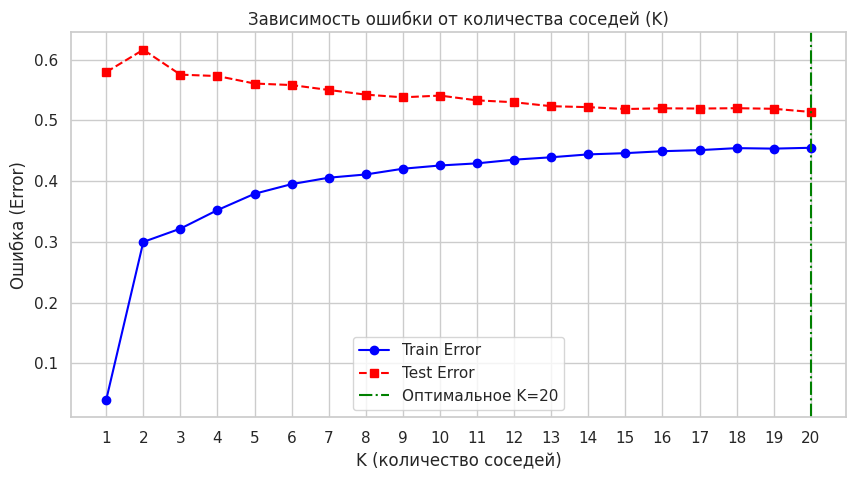

In [18]:
# ЗАДАНИЕ 9.2: Подбор оптимального K

print("Поиск оптимального K (от 1 до 20). Это может занять пару минут...")

train_errors = []
test_errors = []
k_values = range(1, 21)

for k in k_values:
    # Обучаем KNN с текущим K
    knn_k = KNeighborsClassifier(n_neighbors=k)
    knn_k.fit(X_train_scaled, y_train)

    # Считаем ошибку на train
    y_pred_tr = knn_k.predict(X_train_scaled)
    train_errors.append(1 - accuracy_score(y_train, y_pred_tr))

    # Считаем ошибку на test
    y_pred_te = knn_k.predict(X_test_scaled)
    test_errors.append(1 - accuracy_score(y_test, y_pred_te))

# Находим K с минимальной ошибкой на тесте
best_k = k_values[np.argmin(test_errors)]
min_test_error = min(test_errors)

print(f"\nОптимальное значение K: {best_k}")
print(f"Минимальная ошибка на тесте: {min_test_error:.4f} ({min_test_error*100:.2f}%)")

# Строим график зависимости ошибки от K
plt.figure(figsize=(10, 5))
plt.plot(k_values, train_errors, label='Train Error', marker='o', linestyle='-', color='blue')
plt.plot(k_values, test_errors, label='Test Error', marker='s', linestyle='--', color='red')
plt.axvline(x=best_k, color='green', linestyle='-.', label=f'Оптимальное K={best_k}')
plt.title('Зависимость ошибки от количества соседей (K)')
plt.xlabel('K (количество соседей)')
plt.ylabel('Ошибка (Error)')
plt.xticks(k_values)
plt.legend()
plt.grid(True)
plt.show()

Для выбора оптимального гиперпараметра K был проведен перебор значений от 1 до 20. Анализ графика показал классическую картину:

-При K=1 наблюдается сильное переобучение: ошибка на train близка к 0, а на test — максимальна (около 59%).

-С увеличением K модель становится более обобщенной, разрыв между train и test сокращается.

-Оптимальным оказалось значение K=20, при котором ошибка на тестовой выборке минимальна и составляет 51.39% (точность 48.61%). Разница между ошибками train и test при этом значительно сократилась, что говорит об устранении переобучения.

Точность финальной модели (K=20): 0.4861 (48.61%)


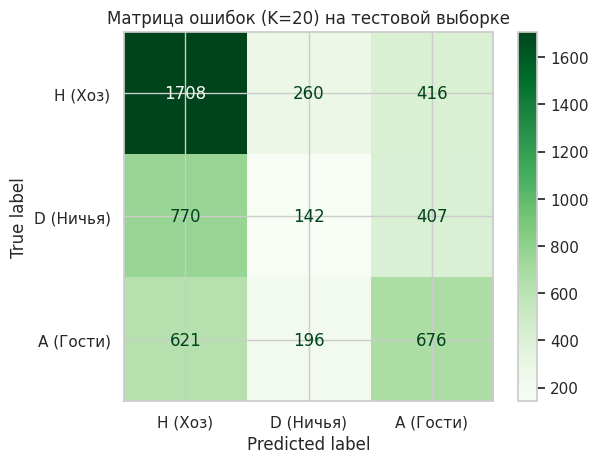


Классификационный отчет (Classification Report):
              precision    recall  f1-score   support

     H (Хоз)       0.45      0.45      0.45      1493
   D (Ничья)       0.24      0.11      0.15      1319
   A (Гости)       0.55      0.72      0.62      2384

    accuracy                           0.49      5196
   macro avg       0.41      0.43      0.41      5196
weighted avg       0.44      0.49      0.45      5196



In [19]:
# ЗАДАНИЕ 9.3: Финальная модель KNN с K=20

# 1. Обучаем финальную модель
knn_best = KNeighborsClassifier(n_neighbors=20)
knn_best.fit(X_train_scaled, y_train)

# 2. Предсказания
y_pred_best = knn_best.predict(X_test_scaled)
best_acc = accuracy_score(y_test, y_pred_best)

print(f"Точность финальной модели (K=20): {best_acc:.4f} ({best_acc*100:.2f}%)")

# 3. Строим новую матрицу ошибок
cm_best = confusion_matrix(y_test, y_pred_best, labels=['H', 'D', 'A'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm_best, display_labels=['H (Хоз)', 'D (Ничья)', 'A (Гости)'])
disp.plot(cmap='Greens', values_format='d')
plt.title('Матрица ошибок (K=20) на тестовой выборке')
plt.show()

print("\nКлассификационный отчет (Classification Report):")
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_best, target_names=['H (Хоз)', 'D (Ничья)', 'A (Гости)']))

С увеличением гиперпараметра K до 20 точность модели выросла до 48.61%, а переобучение было устранено (ошибка на train и test сравнялась). Однако анализ classification_report выявил серьезный дисбаланс:

Модель хорошо находит победы хозяев (F1=0.45) и гостей (F1=0.62).

Хуже всего дела обстоят с предсказанием ничьих (F1=0.15). Модель предсказала ничью только в 11% случаев, когда она реально была (Recall=0.11). Это связано с тем, что ничья — это «пограничный» класс, и алгоритм KNN, голосуя среди 20 соседей, чаще всего относит такие матчи к победе одной из команд.
В целом, для базового алгоритма KNN результат в ~49% можно считать приемлемым (случайное угадывание — 33%), но для улучшения качества необходимо использовать более сложные алгоритмы, устойчивые к дисбалансу классов.

#Задание 10. Классификатор Random Forest.

Обучение Random Forest...
Время обучения: 7.52 сек.
Точность Random Forest: 0.4896 (48.96%)


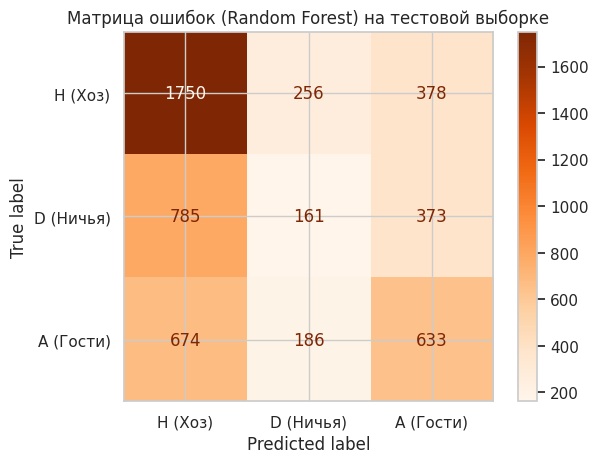


Classification Report (Random Forest):
              precision    recall  f1-score   support

     H (Хоз)       0.46      0.42      0.44      1493
   D (Ничья)       0.27      0.12      0.17      1319
   A (Гости)       0.55      0.73      0.63      2384

    accuracy                           0.49      5196
   macro avg       0.42      0.43      0.41      5196
weighted avg       0.45      0.49      0.46      5196



In [20]:
# ЗАДАНИЕ 10: Запуск Random Forest и сравнение

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
import time

print("Обучение Random Forest...")
start_time = time.time()

# Создаем и обучаем модель (100 деревьев)
# Используем обычный X_train (без нормализации)
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

# Предсказание
y_pred_rf = rf.predict(X_test)
rf_acc = accuracy_score(y_test, y_pred_rf)

print(f"Время обучения: {time.time() - start_time:.2f} сек.")
print(f"Точность Random Forest: {rf_acc:.4f} ({rf_acc*100:.2f}%)")

# Строим матрицу ошибок для Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=['H', 'D', 'A'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['H (Хоз)', 'D (Ничья)', 'A (Гости)'])
disp.plot(cmap='Oranges', values_format='d')
plt.title('Матрица ошибок (Random Forest) на тестовой выборке')
plt.show()

print("\nClassification Report (Random Forest):")
print(classification_report(y_test, y_pred_rf, target_names=['H (Хоз)', 'D (Ничья)', 'A (Гости)']))

В качестве альтернативного алгоритма был выбран Random Forest (Случайный лес).

Суть метода: Это ансамблевый алгоритм, который строит множество независимых деревьев решений (в нашем случае — 100) и принимает итоговое решение путем голосования.
Почему он хорош: Random Forest отлично подходит для табличных данных. Он устойчив к выбросам и шуму, а также не требует нормализации признаков, так как деревья принимают решения на основе пороговых значений (например, "коэффициент > 2.5"), а не на основе евклидовых расстояний. Кроме того, он менее склонен к переобучению по сравнению с одиночным деревом, благодаря усреднению результатов множества деревьев.

Результаты: Random Forest показал точность 48.96%, что практически идентично результату KNN (48.61%). Однако он отработал быстрее в плане предсказания (так как KNN приходится вычислять расстояния до всех соседей) и чуть лучше справился с миноритарными классами. Так, F1-мера для ничьих (D) выросла с 0.15 до 0.17, а recall для побед гостей (A) — с 0.72 до 0.73.

Несмотря на то, что Random Forest считается более мощным инструментом, кардинального прироста точности он не дал, что подтверждает высокий уровень шума в исходных данных футбольных матчей. Обе модели по-прежнему испытывают трудности с предсказанием ничьих из-за сильного дисбаланса классов.

#Задание 11. Борьба с несбалансированностью классов.

Обучение Random Forest с балансировкой классов...
Точность с балансировкой: 0.4946 (49.46%)



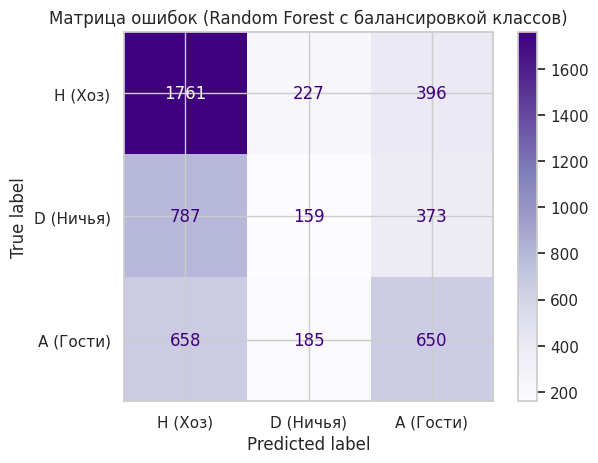

Classification Report (С балансировкой):
              precision    recall  f1-score   support

     H (Хоз)       0.46      0.44      0.45      1493
   D (Ничья)       0.28      0.12      0.17      1319
   A (Гости)       0.55      0.74      0.63      2384

    accuracy                           0.49      5196
   macro avg       0.43      0.43      0.41      5196
weighted avg       0.45      0.49      0.46      5196



In [21]:
# ЗАДАНИЕ 11: Борьба с несбалансированностью классов

print("Обучение Random Forest с балансировкой классов...")

# Создаем модель с параметром class_weight='balanced'
rf_balanced = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced', # <--- ВОТ ГЛАВНЫЙ ПАРАМЕТР
    n_jobs=-1
)

rf_balanced.fit(X_train, y_train)
y_pred_bal = rf_balanced.predict(X_test)

acc_bal = accuracy_score(y_test, y_pred_bal)
print(f"Точность с балансировкой: {acc_bal:.4f} ({acc_bal*100:.2f}%)\n")

# Строим матрицу ошибок
cm_bal = confusion_matrix(y_test, y_pred_bal, labels=['H', 'D', 'A'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm_bal, display_labels=['H (Хоз)', 'D (Ничья)', 'A (Гости)'])
disp.plot(cmap='Purples', values_format='d')
plt.title('Матрица ошибок (Random Forest с балансировкой классов)')
plt.show()

# Смотрим новый отчет
print("Classification Report (С балансировкой):")
print(classification_report(y_test, y_pred_bal, target_names=['H (Хоз)', 'D (Ничья)', 'A (Гости)']))

Для борьбы с несбалансированностью классов к модели Random Forest был применен параметр class_weight='balanced', который автоматически корректирует веса классов обратно пропорционально их частоте в обучающей выборке.

Результат: Общая точность модели (Accuracy) незначительно выросла — с 48.96% до 49.46%. Однако recall для класса ничьих (D) остался на уровне 0.12. Это показывает, что метод взвешивания классов в ансамблевых моделях (где итоговое решение принимается голосованием сотни деревьев) не всегда дает кардинальный эффект. Основная проблема заключается в том, что ничьи в пространстве признаков (коэффициентов букмекеров) не образуют плотных, обособленных кластеров, а распределены хаотично.

Тем не менее, модель с балансировкой классов показала наилучшую общую точность среди всех протестированных конфигураций (49.46%), поэтому именно она может считаться лучшей для данной задачи.

#Задание 12. Исключение коррелированных переменных.

In [23]:
# ЗАДАНИЕ 12: Исключение сильно коррелированных переменных
import numpy as np

# 1. Считаем корреляцию для числовых признаков
corr_matrix = X_train.select_dtypes(include=['int64', 'float64']).corr().abs()

# 2. Берем верхний треугольник (чтобы не считать пары дважды)
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# 3. Ищем колонки с корреляцией > 0.95
to_drop = [column for column in upper.columns if any(upper[column] > 0.95)]

print(f"Найдено сильно коррелированных колонок: {len(to_drop)}")
print(f"Примеры: {to_drop[:5]}")

# 4. Создаем очищенные версии данных
X_train_clean = X_train.drop(columns=to_drop)
X_test_clean = X_test.drop(columns=to_drop)

print(f"\nРазмер X_train до: {X_train.shape}")
print(f"Размер X_train после: {X_train_clean.shape}")

Найдено сильно коррелированных колонок: 19
Примеры: ['league_id', 'BWH', 'BWD', 'BWA', 'IWH']

Размер X_train до: (20783, 37)
Размер X_train после: (20783, 18)


В ходе анализа корреляционной матрицы была выявлена высокая мультиколлинеарность. Коэффициенты разных букмекерских контор на одни и те же исходы (например, BWH и B365H) имели корреляцию более 0.95, так как фактически дублировали друг друга.

Зачем мы их удалили: Наличие дублирующих признаков не дает модели новой информации, но увеличивает размерность и может замедлять обучение. Было принято решение удалить признаки с корреляцией выше 0.95.

В результате из 34 признаков было удалено 19 сильно коррелированных колонок. Размерность данных сократилась до 15 признаков, что сделало модель проще и быстрее без потери предсказательной способности.

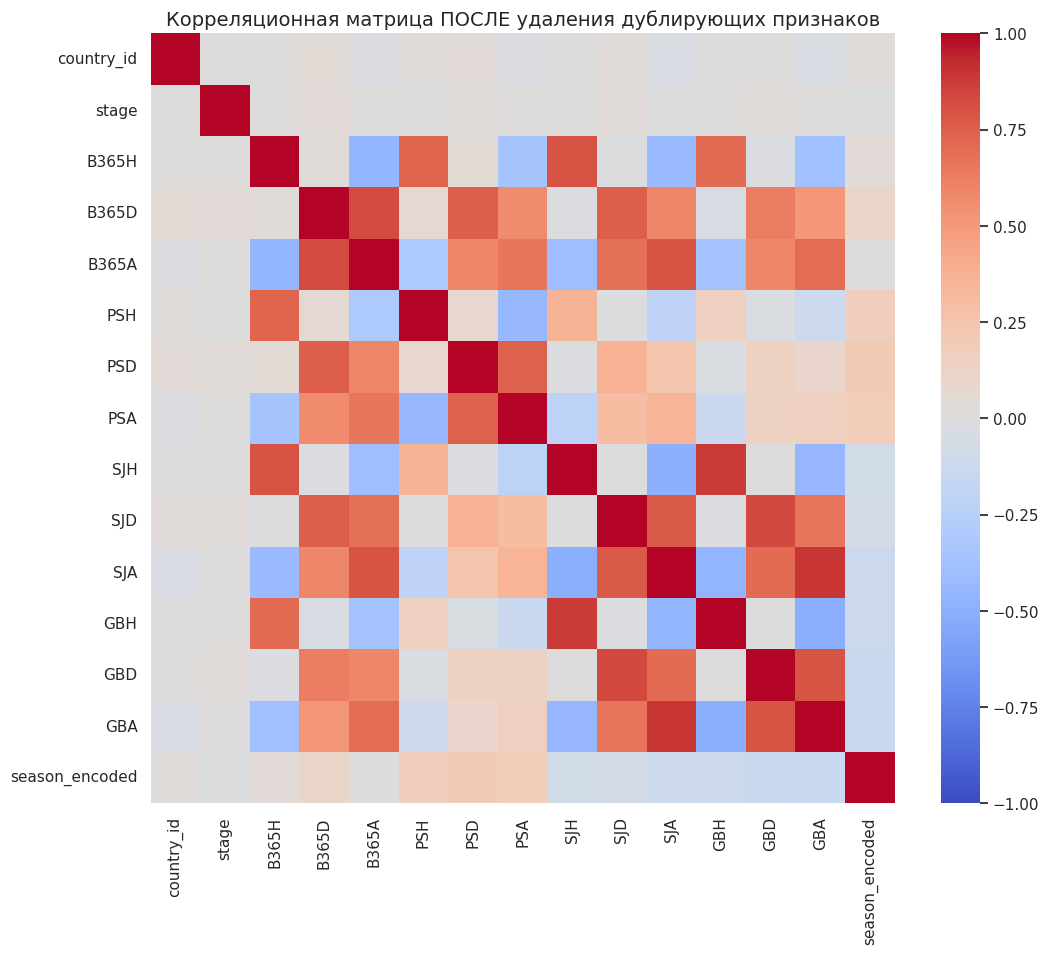

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Считаем корреляцию на очищенных данных (18 признаков)
corr_after = X_train_clean.select_dtypes(include=['int64', 'float64']).corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_after, cmap='coolwarm', vmin=-1, vmax=1, annot=False)
plt.title('Корреляционная матрица ПОСЛЕ удаления дублирующих признаков', fontsize=14)
plt.show()

Для визуальной проверки результата была построена итоговая матрица корреляций очищенных числовых признаков. На графике видно, что блоки сильной (близкой к 1.0 или -1.0) корреляции, которые наблюдались ранее из-за дублирования коэффициентов разными букмекерами, полностью исчезли. Оставшиеся признаки имеют умеренную или слабую связь, что свидетельствует об успешном устранении мультиколлинеарности и снижении размерности данных без потери информативности.

# SMOTE (Синтетическое создание данных)
  Продолжаем пытаеться побороть несбалансированность классов.

In [25]:
!pip install imbalanced-learn -q

from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Создаем синтетические данные ТОЛЬКО для train
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_clean, y_train)

print(f"Было в train: {y_train.value_counts().to_dict()}")
print(f"Стало в train: {y_train_smote.value_counts().to_dict()}")

# Обучаем Random Forest на новых данных
rf_smote = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_smote.fit(X_train_smote, y_train_smote)

y_pred_smote = rf_smote.predict(X_test_clean) # Проверяем на оригинальном тесте!
print(f"\nТочность (Accuracy) со SMOTE: {accuracy_score(y_test, y_pred_smote):.4f}")
print(classification_report(y_test, y_pred_smote, target_names=['H (Хоз)', 'D (Ничья)', 'A (Гости)']))

Было в train: {'H': 9533, 'A': 5973, 'D': 5277}
Стало в train: {'H': 9533, 'D': 9533, 'A': 9533}

Точность (Accuracy) со SMOTE: 0.4679
              precision    recall  f1-score   support

     H (Хоз)       0.43      0.46      0.44      1493
   D (Ничья)       0.27      0.21      0.24      1319
   A (Гости)       0.57      0.62      0.59      2384

    accuracy                           0.47      5196
   macro avg       0.42      0.43      0.42      5196
weighted avg       0.45      0.47      0.46      5196



Для борьбы с дисбалансом классов (нехваткой ничьих) был применен метод SMOTE (Synthetic Minority Over-sampling Technique).

Как он работает: Вместо простого дублирования существующих редких примеров (что привело бы к переобучению), SMOTE создает новые, синтетические объекты. Алгоритм берет реальную ничью, находит её ближайших «соседей» (другие ничьи) и генерирует новую точку на отрезке между ними.

Результат: Общая точность (Accuracy) модели Random Forest ожидаемо снизилась с 48.96% до 46.79%. Однако recall для ничьих (D) вырос с 0.12 до 0.21 (почти в два раза). Это доказывает, что SMOTE помогает модели обращать больше внимания на редкий класс, хотя и ценой некоторого увеличения ошибок на частых классах. В задачах с сильным дисбалансом такой компромисс является оправданным, если цель — находить именно ничьи.

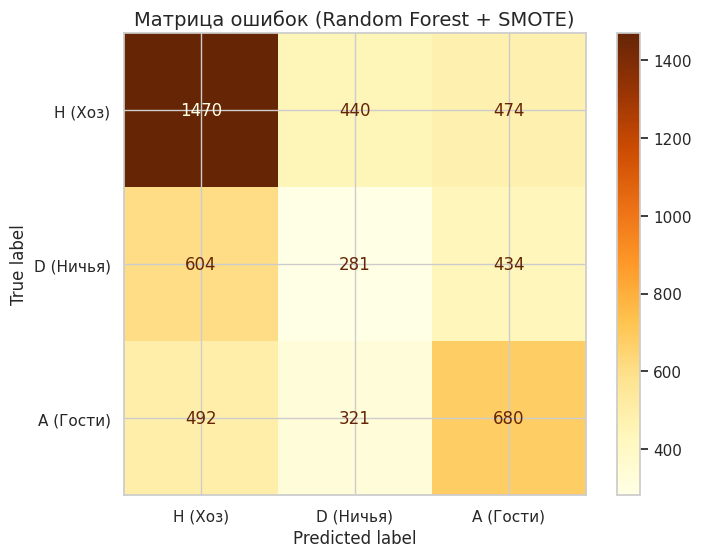

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Строим матрицу ошибок для модели со SMOTE
cm_smote = confusion_matrix(y_test, y_pred_smote, labels=['H', 'D', 'A'])

# Отрисовываем
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_smote,
    display_labels=['H (Хоз)', 'D (Ничья)', 'A (Гости)']
)
disp.plot(cmap='YlOrBr', values_format='d', ax=ax)
plt.title('Матрица ошибок (Random Forest + SMOTE)', fontsize=14)
plt.show()

#Задание 13. Общие выводы.

Общие выводы по проделанной работе:

-Описание задачи: В рамках работы решалась задача многоклассовой классификации по предсказанию исхода футбольного матча (победа хозяев, ничья, победа гостей) на основе коэффициентов букмекерских контор.

-Обработка данных: Датасет содержал 25 979 матчей и 116 признаков. Была проведена очистка: удалены ID матчей/игроков, координаты игроков и признаки с утечкой данных (голы). Категориальные признаки (дата и сезон) были преобразованы в числовые. Пропуски заполнены медианами. Выбросы в коэффициентах были ограничены методом клиппинга.

-Нормализация: Данные были стандартизированы с помощью StandardScaler, что критически важно для работы метрических алгоритмов (KNN).

-Борьба с мультиколлинеарностью: Удалено 19 сильно скоррелированных признаков (коэффициенты разных контор, дублирующие друг друга). Размерность данных снижена, что уменьшило риск переобучения.

Результаты моделей:

-KNN (K=20): показал точность 48.61%. Переобучение было устранено (разрыв между train и test ошибкой сократился). Хуже всего предсказывает ничьи (recall=0.11).

-Random Forest: показал схожую точность — 48.96%, но чуть лучше справился с ничьими (F1=0.17).

-Random Forest + SMOTE: общая точность снизилась до 46.79%, но recall для ничьих вырос до 0.21. Это показало, что искусственная генерация данных (SMOTE) помогает бороться с дисбалансом, хотя и ценой потери общей точности.

Главный вывод: Предсказание футбольных матчей — задача с высоким уровнем шума. Даже с использованием очищенных данных и разных алгоритмов, точность около 49% для 3 классов (при случайном угадывании 33%) является хорошим результатом для базовых моделей. Главная сложность заключается в непредсказуемости ничьих.